# Results Visualization


In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## Paths


In [2]:
import runpy

config_path = Path.cwd() / 'config.py'
if not config_path.is_file():
    config_path = Path.cwd().parent / 'config.py'
config = runpy.run_path(str(config_path))
run_dir = config['run_dir']

cnn_history_path = run_dir / 'cnn_training_history.csv'
cnn_summary_path = run_dir / 'cnn_training_summary.json'
statistical_model_path = run_dir / 'best_statistical_model.joblib'
global_metrics_path = run_dir / 'global_test_segment_metrics.csv'
global_summary_path = run_dir / 'global_test_summary.csv'
performance_summary_path = run_dir / 'model_performance_summary.csv'

figure_paths = {
    'cnn_learning_curves': run_dir / 'cnn_learning_curves',
    'mlp_learning_curve': run_dir / 'mlp_learning_curve',
    'cnn_global_metrics': run_dir / 'cnn_global_rfi_metrics',
    'mlp_global_metrics': run_dir / 'mlp_global_rfi_metrics',
    'global_comparison': run_dir / 'global_rfi_metric_comparison',
    'performance': run_dir / 'model_inference_performance'
}
replace_existing_figures = True

for input_path in (
    cnn_history_path, cnn_summary_path, statistical_model_path,
    global_metrics_path, global_summary_path, performance_summary_path
):
    if not input_path.is_file():
        raise FileNotFoundError(f'Input file not found: {input_path}')

if not replace_existing_figures:
    for figure_path in figure_paths.values():
        if figure_path.with_suffix('.png').exists() or figure_path.with_suffix('.pdf').exists():
            raise FileExistsError(f'Figure output already exists: {figure_path}')


## Load Results


In [3]:
cnn_history = pd.read_csv(cnn_history_path)
required_history_columns = {
    'epoch', 'train_loss', 'train_accuracy',
    'validation_loss', 'validation_accuracy'
}
if set(cnn_history.columns) != required_history_columns or len(cnn_history) != 50:
    raise ValueError('CNN training history has an unexpected schema')

with cnn_summary_path.open(encoding='utf-8') as handle:
    cnn_summary = json.load(handle)
if cnn_summary.get('n_epochs') != len(cnn_history):
    raise ValueError('CNN training summary does not match the history')

statistical_model = joblib.load(statistical_model_path)
required_bundle_keys = {
    'model_name', 'feature_columns', 'threshold', 'pipeline',
    'validation_metrics', 'test_metrics'
}
if set(statistical_model) != required_bundle_keys:
    raise ValueError('Statistical-model bundle has an unexpected schema')
mlp_classifier = statistical_model['pipeline'].named_steps.get('clf')
if not hasattr(mlp_classifier, 'loss_curve_'):
    raise ValueError('Selected statistical model does not contain a training loss curve')
mlp_loss_curve = np.asarray(mlp_classifier.loss_curve_, dtype=float)
if len(mlp_loss_curve) == 0 or not np.isfinite(mlp_loss_curve).all():
    raise ValueError('MLP training loss curve is invalid')

global_metrics = pd.read_csv(global_metrics_path)
global_summary = pd.read_csv(global_summary_path)
performance_summary = pd.read_csv(performance_summary_path)

required_global_columns = {'model', 'segment_type', 'accuracy', 'precision', 'recall', 'f1'}
if not required_global_columns.issubset(global_metrics.columns):
    raise ValueError('Global-test metrics have an unexpected schema')
required_performance_columns = {
    'model', 'device', 'n_segments', 'p95_ms', 'segment_budget_ms'
}
if not required_performance_columns.issubset(performance_summary.columns):
    raise ValueError('Performance summary has an unexpected schema')

print('CNN epochs:', len(cnn_history))
print('CNN training device:', cnn_summary['device'])
print('MLP iterations:', len(mlp_loss_curve))
print('Global-test rows:', len(global_metrics))
print('Performance rows:', len(performance_summary))


CNN epochs: 50
CNN training device: cuda
MLP iterations: 172
Global-test rows: 28418
Performance rows: 3


## Save Figures


In [4]:
def save_figure(figure, figure_path):
    png_path = figure_path.with_suffix('.png')
    #pdf_path = figure_path.with_suffix('.pdf')
    figure.savefig(png_path, dpi=300, bbox_inches='tight')
    #figure.savefig(pdf_path, bbox_inches='tight')
    plt.show()
    plt.close(figure)
    print('Saved:', png_path)
    #print('Saved:', pdf_path)


## CNN Training


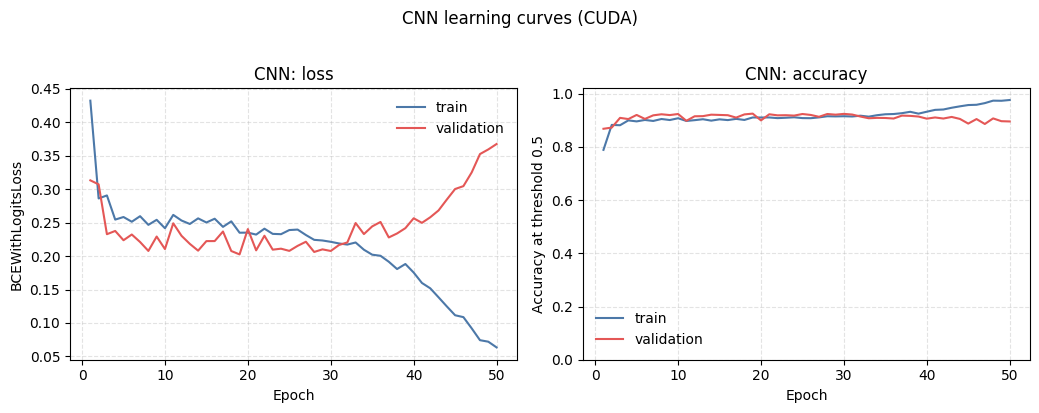

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/cnn_learning_curves.png


In [5]:
fig, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(10.5, 4.0))

loss_axis.plot(cnn_history['epoch'], cnn_history['train_loss'], label='train', color='#4C78A8')
loss_axis.plot(cnn_history['epoch'], cnn_history['validation_loss'], label='validation', color='#E45756')
loss_axis.set(
    xlabel='Epoch',
    ylabel='BCEWithLogitsLoss',
    title='CNN: loss'
)
loss_axis.grid(linestyle='--', alpha=0.35)
loss_axis.legend(frameon=False)

accuracy_axis.plot(cnn_history['epoch'], cnn_history['train_accuracy'], label='train', color='#4C78A8')
accuracy_axis.plot(cnn_history['epoch'], cnn_history['validation_accuracy'], label='validation', color='#E45756')
accuracy_axis.set(
    xlabel='Epoch',
    ylabel='Accuracy at threshold 0.5',
    title='CNN: accuracy',
    ylim=(0, 1.02)
)
accuracy_axis.grid(linestyle='--', alpha=0.35)
accuracy_axis.legend(frameon=False)

fig.suptitle(f"CNN learning curves ({cnn_summary['device'].upper()})", y=1.02)
fig.tight_layout()
save_figure(fig, figure_paths['cnn_learning_curves'])


## MLP Training


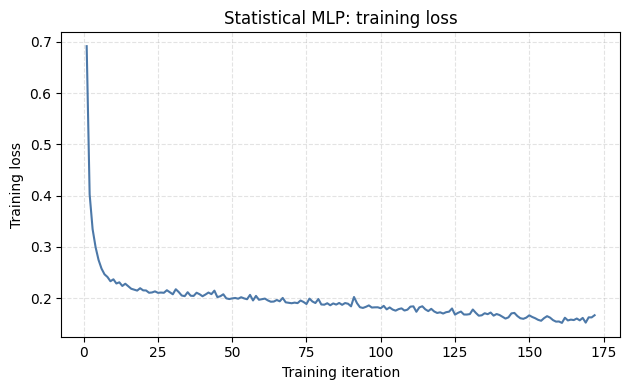

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/mlp_learning_curve.png


In [6]:
fig, axis = plt.subplots(figsize=(6.4, 4.0))
axis.plot(np.arange(1, len(mlp_loss_curve) + 1), mlp_loss_curve, color='#4C78A8')
axis.set(
    xlabel='Training iteration',
    ylabel='Training loss',
    title=f"Statistical {statistical_model['model_name']}: training loss"
)
axis.grid(linestyle='--', alpha=0.35)
fig.tight_layout()
save_figure(fig, figure_paths['mlp_learning_curve'])


## Global Test Distributions


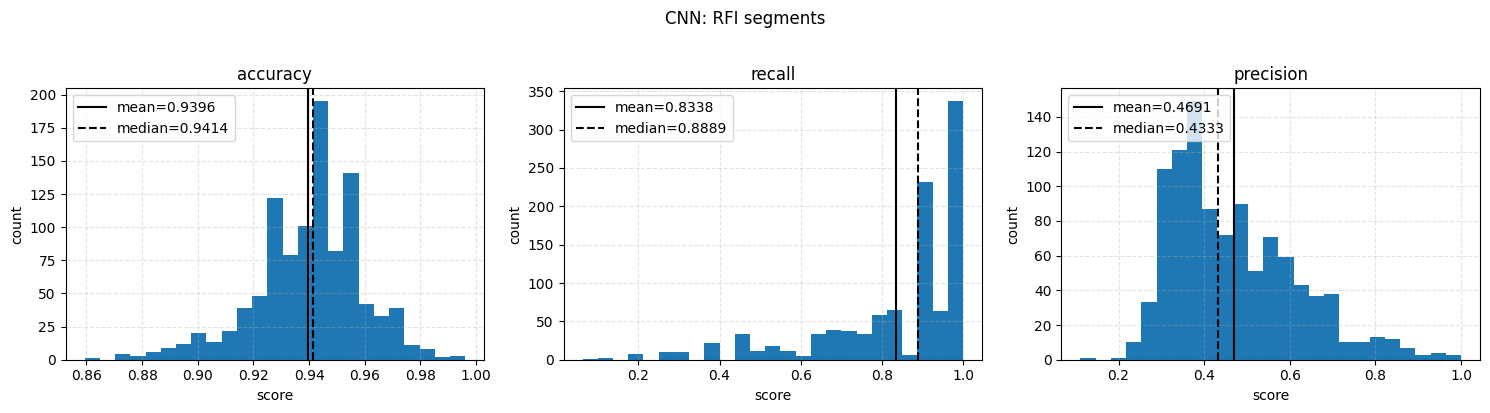

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/cnn_global_rfi_metrics.png


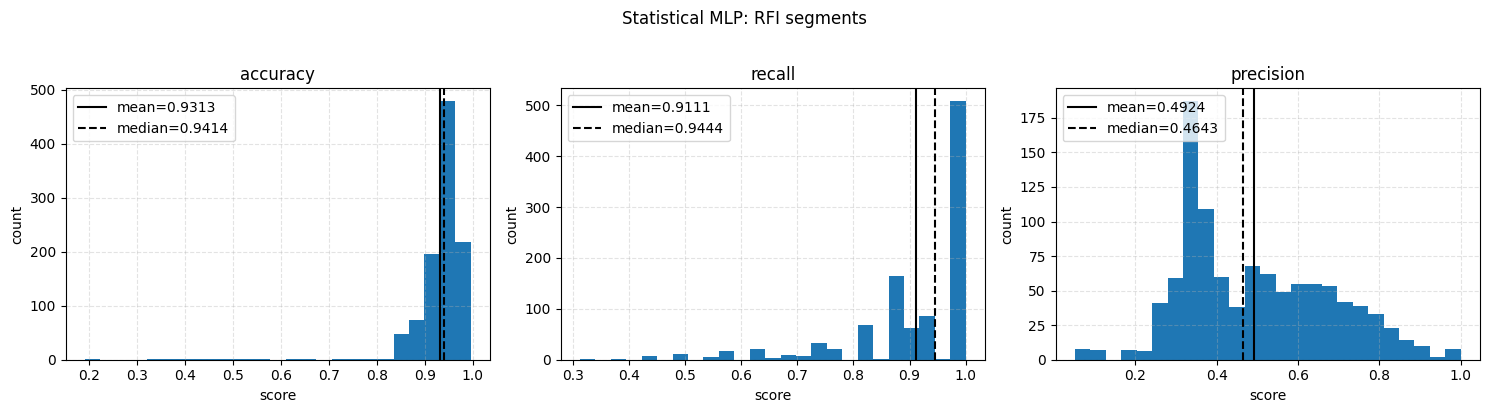

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/mlp_global_rfi_metrics.png


In [7]:
def plot_rfi_metric_distributions(model_name, figure_path):
    metric_names = ['accuracy', 'recall', 'precision']
    rfi_metrics = global_metrics.loc[
        global_metrics['model'].eq(model_name) & global_metrics['segment_type'].eq('RFI'),
        metric_names
    ]
    if rfi_metrics.empty or rfi_metrics.isna().any().any():
        raise ValueError(f'RFI metrics are invalid for {model_name}')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
    for axis, metric_name in zip(axes, metric_names):
        values = rfi_metrics[metric_name].to_numpy(dtype=float)
        mean_value = values.mean()
        median_value = np.median(values)
        axis.hist(values, bins=25, color='#1f77b4')
        axis.axvline(mean_value, color='black', linewidth=1.5, label=f'mean={mean_value:.4f}')
        axis.axvline(median_value, color='black', linestyle='--', linewidth=1.5, label=f'median={median_value:.4f}')
        axis.set(xlabel='score', ylabel='count', title=metric_name)
        axis.grid(linestyle='--', alpha=0.35)
        axis.legend(frameon=True, loc='upper left')

    fig.suptitle(f'{model_name}: RFI segments', y=1.02)
    fig.tight_layout()
    save_figure(fig, figure_path)


cnn_model_name = 'CNN'
statistical_model_name = f"Statistical {statistical_model['model_name']}"
plot_rfi_metric_distributions(cnn_model_name, figure_paths['cnn_global_metrics'])
plot_rfi_metric_distributions(statistical_model_name, figure_paths['mlp_global_metrics'])


## Global Test Comparison


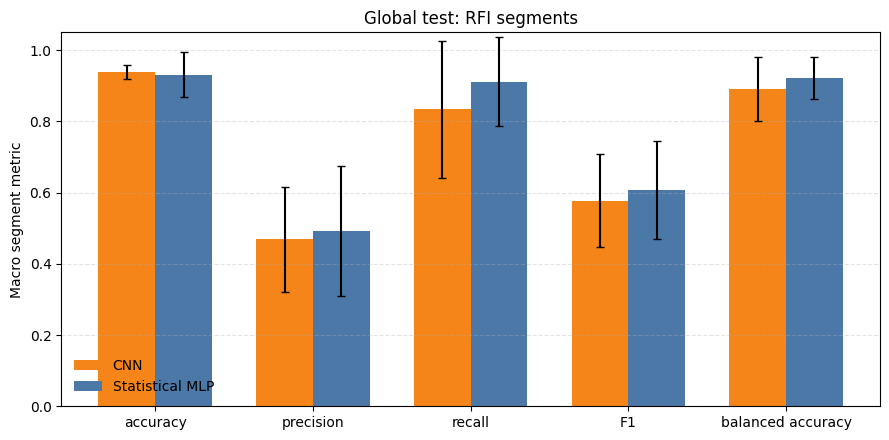

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/global_rfi_metric_comparison.png


In [8]:
comparison_metrics = ['accuracy', 'precision', 'recall', 'f1', 'balanced_accuracy']
rfi_summary = global_summary.loc[
    global_summary['segment_type'].eq('RFI') & global_summary['model'].isin([cnn_model_name, statistical_model_name])
].set_index('model')
if set(rfi_summary.index) != {cnn_model_name, statistical_model_name}:
    raise ValueError('Global-test summary does not contain both selected models')

fig, axis = plt.subplots(figsize=(9.0, 4.5))
positions = np.arange(len(comparison_metrics))
bar_width = 0.36
for offset, model_name, label, color in (
    (-bar_width / 2, cnn_model_name, 'CNN', '#F58518'),
    (bar_width / 2, statistical_model_name, f"Statistical {statistical_model['model_name']}", '#4C78A8')
):
    values = [rfi_summary.loc[model_name, f'macro_{metric}'] for metric in comparison_metrics]
    errors = [rfi_summary.loc[model_name, f'macro_{metric}_std'] for metric in comparison_metrics]
    axis.bar(positions + offset, values, bar_width, yerr=errors, capsize=3, label=label, color=color)

axis.set(
    xticks=positions,
    xticklabels=['accuracy', 'precision', 'recall', 'F1', 'balanced accuracy'],
    ylabel='Macro segment metric',
    title='Global test: RFI segments',
    ylim=(0, 1.05)
)
axis.grid(axis='y', linestyle='--', alpha=0.35)
axis.legend(frameon=False)
fig.tight_layout()
save_figure(fig, figure_paths['global_comparison'])


## Model Performance


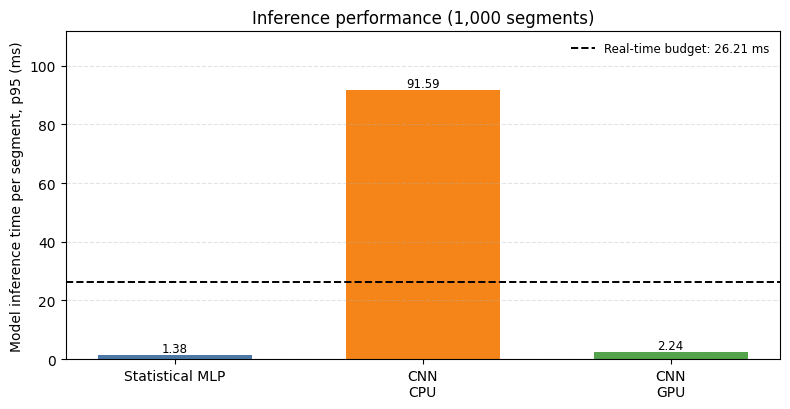

Saved: /u/akazantsev/ml_dl_for_rfi_mitigation/runs/punch_rfi_reproduction/model_inference_performance.png


In [9]:
performance_order = [
    (statistical_model_name, 'cpu', f"Statistical {statistical_model['model_name']}"),
    ('CNN', 'cpu', 'CNN\nCPU'),
    ('CNN', 'cuda', 'CNN\nGPU')
]
colors = ['#4C78A8', '#F58518', '#54A24B']

performance_values = []
for model_name, device_name, label in performance_order:
    row = performance_summary.loc[
        performance_summary['model'].eq(model_name) & performance_summary['device'].eq(device_name)
    ]
    if len(row) != 1:
        raise ValueError(f'Expected one performance row for {model_name} on {device_name}')
    performance_values.append((label, float(row.iloc[0]['p95_ms'])))

budget_values = performance_summary['segment_budget_ms'].unique()
if len(budget_values) != 1:
    raise ValueError('Performance summary has inconsistent segment budgets')
segment_budget_ms = float(budget_values[0])

fig, axis = plt.subplots(figsize=(8.0, 4.2))
positions = np.arange(len(performance_values))
labels = [label for label, _ in performance_values]
p95_values = [value for _, value in performance_values]
bars = axis.bar(positions, p95_values, color=colors, width=0.62)
axis.axhline(
    segment_budget_ms,
    color='black',
    linestyle='--',
    linewidth=1.4,
    label=f'Real-time budget: {segment_budget_ms:.2f} ms'
)
axis.set(
    xticks=positions,
    xticklabels=labels,
    ylabel='Model inference time per segment, p95 (ms)',
    title='Inference performance (1,000 segments)'
)
axis.grid(axis='y', linestyle='--', alpha=0.35)
axis.legend(frameon=False, loc='upper right', fontsize=8.5)
axis.set_ylim(0, max(max(p95_values), segment_budget_ms) * 1.22)

for bar, value in zip(bars, p95_values):
    axis.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}',
        ha='center',
        va='bottom',
        fontsize=8.5
    )

fig.tight_layout()
save_figure(fig, figure_paths['performance'])
